# RF User Segmentation

#### Business Question:

- Which customer groups generate the greatest long-term value, and which groups should the business prioritize for retention?

*NOTE*
- Since transaction value is unavailable in the RetailRocket dataset, customer segmentation is performed using Recency and Frequency (RF) instead of traditional RFM.

In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [52]:
rf= pd.read_csv(r"C:\Users\Pavni Rastogi\Desktop\product-analytics-case-study\csv-files\rf_segmentation.csv")
rf.head()

,visitorid,recency,frequency,r_score,f_score,rf_score,customer_segment,segment_order
0,673776,138,1,1,1,11,Inactive users,6
1,996991,138,1,1,1,11,Inactive users,6
2,266417,138,2,1,4,14,Declining users,5
3,729806,138,1,1,1,11,Inactive users,6
4,429418,138,3,1,4,14,Declining users,5


In [53]:
rf.shape

(11719, 8)

In [54]:
rf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11719 entries, 0 to 11718
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   visitorid         11719 non-null  int64 
 1   recency           11719 non-null  int64 
 2   frequency         11719 non-null  int64 
 3   r_score           11719 non-null  int64 
 4   f_score           11719 non-null  int64 
 5   rf_score          11719 non-null  int64 
 6   customer_segment  11719 non-null  object
 7   segment_order     11719 non-null  int64 
dtypes: int64(7), object(1)
memory usage: 732.6+ KB


#### segment distribution

In [55]:
rf=rf.sort_values('segment_order')
segment_dist= (rf["customer_segment"].value_counts().reset_index())
segment_dist.columns = ["Segment", "Users"]

segment_dist

,Segment,Users
0,Inactive users,2218
1,Declining users,2216
2,High value users,2209
3,Emerging users,2162
4,Casual users,2147
5,Champions,767


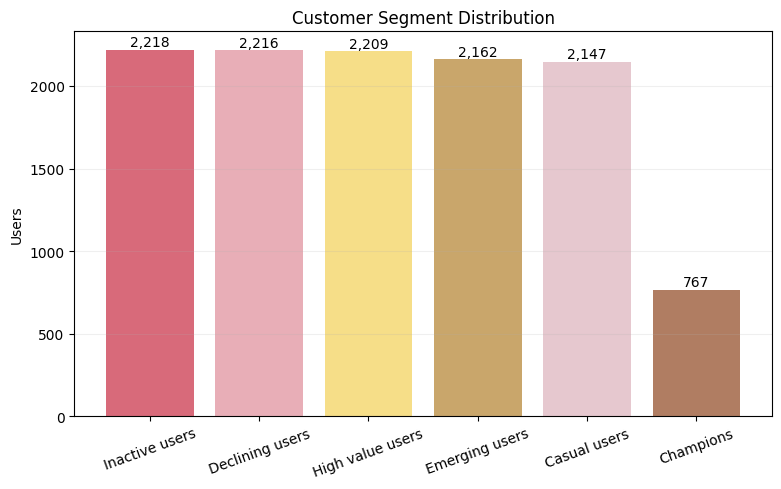

In [56]:
#visualisation:
plt.figure(figsize=(9,5))
colors=[
    "#D86A7A",
    "#E8AEB7",
    "#F6DE88",
    "#C9A66B",
    "#E6C8CF",
    "#B07D62"
]
bars=plt.bar(segment_dist["Segment"], segment_dist["Users"], color=colors)

for bar in bars:
    h=bar.get_height()
    plt.text(bar.get_x()+bar.get_width()/2, h+20, f"{int(h):,}", ha='center')

plt.xticks(rotation=20)
plt.ylabel("Users")
plt.title("Customer Segment Distribution")
plt.grid(axis='y', alpha=0.2)

plt.show()

#### segment profile (mean)

In [57]:
segment_profile=(rf.groupby("customer_segment").agg({"recency":"mean","frequency":"mean"}).round(1))
segment_profile

,recency,frequency
customer_segment,,
Casual users,76.7,2.2
Champions,18.9,6.2
Declining users,97.9,1.8
Emerging users,31.4,1.0
High value users,43.2,2.1
Inactive users,121.5,1.0


In [60]:
print(rf["customer_segment"].unique())

['Champions' 'High value users' 'Emerging users' 'Casual users'
 'Declining users' 'Inactive users']


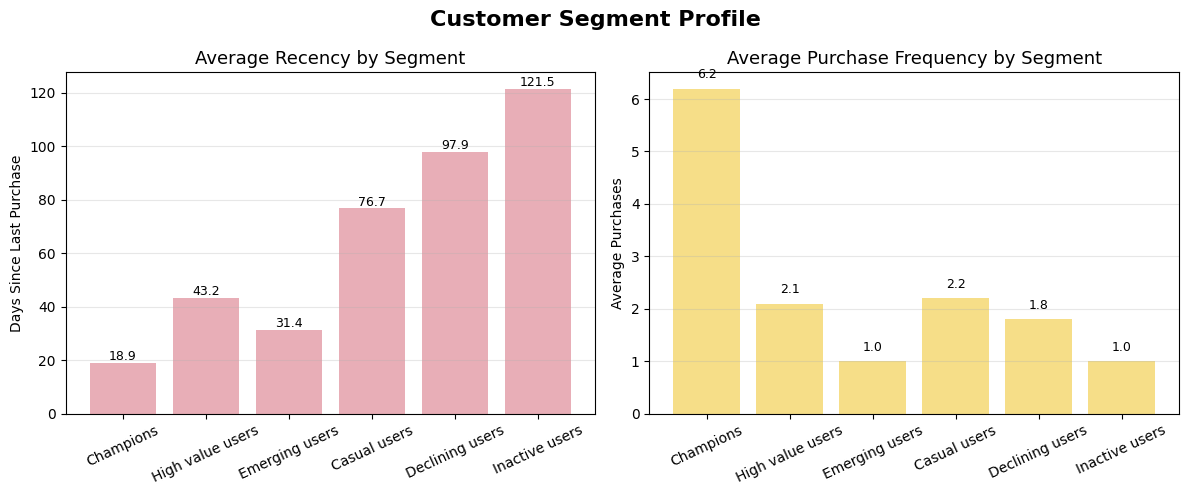

In [62]:
order = ["Champions","High value users","Emerging users", "Casual users", "Declining users", "Inactive users"]
segment_profile = segment_profile.reindex(order)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

#avg recency
ax[0].bar(segment_profile.index, segment_profile["recency"], color="#E8AEB7")

ax[0].set_title("Average Recency by Segment", fontsize=13)
ax[0].set_ylabel("Days Since Last Purchase")
ax[0].tick_params(axis='x', rotation=25)
ax[0].grid(axis='y', alpha=0.3)

for i, v in enumerate(segment_profile["recency"]):
    ax[0].text(i, v + 1, f"{v:.1f}", ha="center", fontsize=9)

#avg frequency
ax[1].bar(segment_profile.index,segment_profile["frequency"], color="#F6DE88")

ax[1].set_title("Average Purchase Frequency by Segment", fontsize=13)
ax[1].set_ylabel("Average Purchases")
ax[1].tick_params(axis='x', rotation=25)
ax[1].grid(axis='y', alpha=0.3)

for i, v in enumerate(segment_profile["frequency"]):
    ax[1].text(i, v + 0.2, f"{v:.1f}", ha="center", fontsize=9)

plt.suptitle("Customer Segment Profile", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

#### RF Heatmap

In [42]:
heatmap_pivot_table=(rf.pivot_table(index="r_score",columns="f_score",values="visitorid",aggfunc="count"))
heatmap_pivot_table

f_score,1,2,3,4
r_score,,,,
1,740,733,745,712
2,757,747,743,683
3,721,732,710,767
4,712,718,732,767


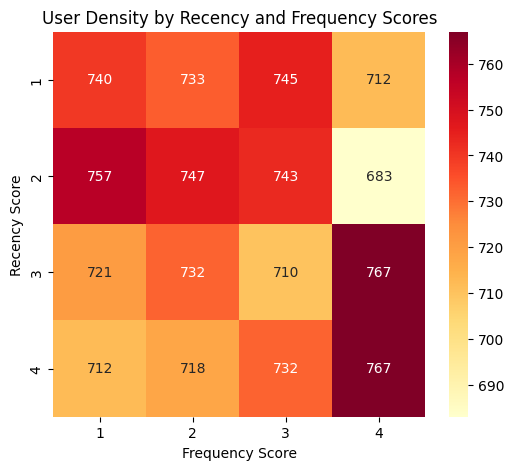

In [44]:
#visual:
plt.figure(figsize=(6,5))
sns.heatmap(heatmap_pivot_table, annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("User Density by Recency and Frequency Scores")
plt.xlabel("Frequency Score")
plt.ylabel("Recency Score")

plt.show()

doesn't really explain much because divison into categories is quartile based.

#### Insights

- but shows that darker areas are champions i.e. 34,44 are highest values customers. 

- Hence, 'champions' represent a relatively small but highly valuable customer segment.

- Casual and Inactive Users account for a substantial share of customers, indicating an opportunity to improve retention.

- Emerging Users represent an ideal audience for personalized campaigns that encourage repeat purchases.

#

### Major Findings

• Overall purchase frequency remains low, with most users making only one purchase.

• Champions and High-Value Users represent the most valuable customers and should be prioritized for loyalty initiatives.

• Emerging Users demonstrate recent engagement but require retention strategies to become repeat purchasers.

• Declining and Inactive Users indicate significant re-engagement opportunities.

### Business Implication

The platform successfully acquires customers but has considerable room to improve repeat purchasing and long-term customer retention.